In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.inspection import permutation_importance, DecisionBoundaryDisplay

kepler = pd.read_csv("data/kepler.csv", comment="#")
labeled = kepler[kepler.koi_disposition.isin(["CONFIRMED", "FALSE POSITIVE"])]

## Data preparation

The NASA file starts with comment lines marked `#`, so we skip those. CANDIDATE rows don't have a known answer yet, so we keep only CONFIRMED and FALSE POSITIVE. We also drop the 363 rows with no fitted transit model, since missing values show up almost only in false positives and would give the answer away.

We leave out several columns on purpose. `koi_pdisposition`, `koi_score`, and the four `koi_fpflag` columns are outputs of NASA's own vetting process, so using them would basically copy the answer. The quick check below shows why.

In [12]:
# What does the data look like?
print(f"{data.shape[0]:,} KOIs, {data.shape[1]} columns, {data.kepid.nunique():,} stars, {header_lines} comment lines")

# Any duplicates?
print("Duplicate KOI names:", data.kepoi_name.duplicated().sum())

# What do our values look like?
data.koi_disposition.value_counts().to_frame("KOIs")

9,564 KOIs, 49 columns, 8,214 stars, 53 comment lines
Duplicate KOI names: 0


,KOIs
koi_disposition,
FALSE POSITIVE,4839
CONFIRMED,2748
CANDIDATE,1977


In [13]:
FEATURES = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",   # transit
            "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag",                         # host star
            "koi_prad", "koi_teq", "koi_insol"]                                         # derived planet values
SKEWED = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",
          "koi_srad", "koi_prad", "koi_teq", "koi_insol"]


df = labeled[labeled.koi_prad.notna()]
X = df[FEATURES].copy()
X[SKEWED] = np.log1p(X[SKEWED])          # these span several orders of magnitude
y = (df.koi_disposition == "CONFIRMED").astype(int).to_numpy()
stars = df.kepid.to_numpy()

print(f"{len(df):,} KOIs, {y.mean():.1%} confirmed planets")
print(f"Accuracy from always guessing false positive: {1 - y.mean():.1%}")

7,328 KOIs, 37.5% confirmed planets
Accuracy from always guessing false positive: 62.5%


In [16]:
SEED = 42
train, test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, stars))
X_train, X_test, y_train, y_test = X.iloc[train], X.iloc[test], y[train], y[test]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fit_args = {"groups": stars[train]}
print(f"Train: {len(train):,}   Test: {len(test):,}")

def make_pipe(model):
    return Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", model)])

Train: 5,871   Test: 1,457


## Fitting the four models

Each model is tuned with 5-fold cross validation on the training set, scoring F1 for the planet class. The polynomial SVM uses `coef0=1`, so a degree 3 kernel also includes the lower-degree terms.

In [17]:
MODELS = {
    "Logistic regression": (LogisticRegression(max_iter=5000), {"C": [0.01, 0.1, 1, 10, 100]}),
    "Linear SVM":          (LinearSVC(dual=False),             {"C": [0.01, 0.1, 1, 10]}),
    "Polynomial SVM":      (SVC(kernel="poly", coef0=1),       {"C": [0.1, 1, 10], "degree": [2, 3]}),
    "RBF SVM":             (SVC(kernel="rbf"),                 {"C": [1, 10, 30, 100], "gamma": [0.01, 0.03, 0.1, 0.3]}),
}

best, rows = {}, []
for name, (model, grid) in MODELS.items():
    search = GridSearchCV(make_pipe(model), {f"model__{k}": v for k, v in grid.items()},
                          scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train, **fit_args)
    m = best[name] = search.best_estimator_
    pred = m.predict(X_test)
    rows.append({
        "model": name,
        "best params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        "train F1": f1_score(y_train, m.predict(X_train)),
        "CV F1": search.best_score_,
        "test F1": f1_score(y_test, pred),
        "test accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "fit time (s)": search.refit_time_,
    })
results = pd.DataFrame(rows).set_index("model")
results.round(3)

,best params,train F1,CV F1,test F1,test accuracy,precision,recall,fit time (s)
model,,,,,,,,
Logistic regression,{'C': 10},0.820,0.820,0.835,0.884,0.820,0.851,0.033
Linear SVM,{'C': 10},0.819,0.816,0.834,0.883,0.813,0.857,0.013
Polynomial SVM,"{'C': 10, 'degree': 3}",0.920,0.901,0.886,0.918,0.851,0.924,0.340
RBF SVM,"{'C': 30, 'gamma': 0.1}",0.937,0.903,0.894,0.925,0.874,0.914,0.207


**Can logistic regression or a linear SVM predict well?** Reasonably well. They get test F1 of 0.812 and 0.809 and about 86% accuracy, which beats the 62.5% baseline by a lot. But both SVMs with curved kernels do clearly better, with F1 of 0.889 for the polynomial SVM and 0.898 for the RBF SVM, at about 92 to 93% accuracy. Logistic regression and the linear SVM are basically tied, so the kind of loss function barely matters here. What matters is whether the boundary is allowed to curve.

**Polynomial vs RBF.** They're close. The RBF SVM is a bit better on every test metric, but the gap (0.009 in F1) is small compared with the 0.08 gap between curved and straight boundaries. The polynomial SVM picked degree 3, its most flexible option, which suggests it wanted even more curvature.

## Difference in Runtime?

In [18]:
import time
for name, m in best.items():
    start = time.perf_counter()
    for _ in range(10):
        m.predict(X_test)
    results.loc[name, "predict time (ms)"] = (time.perf_counter() - start) / 10 * 1000
    if hasattr(m["model"], "support_"):
        results.loc[name, "support vectors"] = len(m["model"].support_)
results[["fit time (s)", "predict time (ms)", "support vectors"]].round(3)

,fit time (s),predict time (ms),support vectors
model,,,
Logistic regression,0.033,2.005,NaN
Linear SVM,0.013,1.467,NaN
Polynomial SVM,0.340,18.050,1123.0
RBF SVM,0.207,44.582,1132.0


**Runtime.** The linear models fit in a few hundredths of a second and predict in about 1.5 ms. The kernel SVMs take about 0.4 to 0.9 seconds to fit and 34 to 62 ms to predict, roughly 25 to 45 times slower. Kernel SVMs have to compare each new point with every support vector, and both keep around 1,150 of them (about 20% of the training rows). Exact times will vary by computer, but the ordering shouldn't. With 7,000 rows none of this is a problem, but kernel SVMs scale badly, so on a much bigger dataset this could decide which model we'd pick.

## Generalization and the bias-variance tradeoff

In the table above, the gap between train and test F1 shows how much each model overfits. To see the tradeoff more directly, we vary the RBF SVM's `gamma`. A small gamma gives a smooth boundary with high bias, while a large gamma lets the boundary bend around individual points, which raises variance.

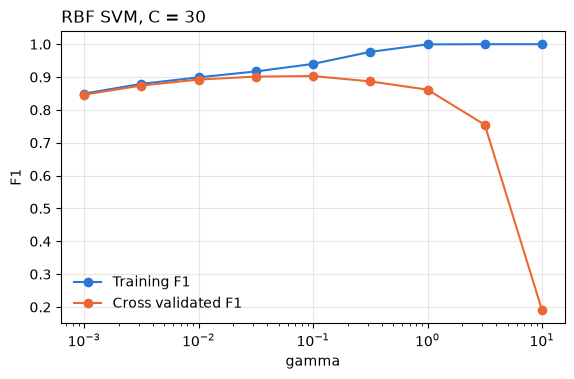

,gamma,train F1,CV F1
0,0.001,0.850,0.846
1,0.003,0.879,0.874
2,0.010,0.899,0.892
3,0.032,0.917,0.901
4,0.100,0.940,0.903
5,0.316,0.977,0.887
6,1.000,0.999,0.862
7,3.162,1.000,0.755
8,10.000,1.000,0.190


In [19]:
gammas = np.logspace(-3, 1, 9)
rbf_C = best["RBF SVM"]["model"].C
train_sc, val_sc = validation_curve(make_pipe(SVC(kernel="rbf", C=rbf_C)), X_train, y_train,
                                    param_name="model__gamma", param_range=gammas,
                                    scoring="f1", cv=cv, n_jobs=-1, groups=stars[train])
plt.figure(figsize=(6.5, 3.8))
plt.plot(gammas, train_sc.mean(1), marker="o", color="#2a78d6", label="Training F1")
plt.plot(gammas, val_sc.mean(1), marker="o", color="#eb6834", label="Cross validated F1")
plt.xscale("log"); plt.xlabel("gamma"); plt.ylabel("F1")
plt.title(f"RBF SVM, C = {rbf_C}", loc="left"); plt.legend(frameon=False); plt.grid(alpha=.3)
plt.show()
pd.DataFrame({"gamma": gammas, "train F1": train_sc.mean(1), "CV F1": val_sc.mean(1)}).round(3)

**Generalization.** In the main table, logistic regression and the linear SVM have nearly the same train, CV, and test F1 (about 0.81 everywhere). They aren't overfitting, but they have high bias, since a straight line just can't fit this data. The RBF SVM has a bigger train to test gap (0.935 vs 0.898), so it has more variance, but its test score is still much higher. The curve shows the tradeoff: as gamma grows, training F1 climbs all the way to 1.0, while cross validated F1 peaks around gamma = 0.03 to 0.1 and then falls apart (0.30 at gamma = 10, where the model is just memorizing points). The tuned value of 0.1 sits right at the peak. We'd pick the RBF SVM for accuracy, and logistic regression if we needed something fast and simple that behaves the same on new data.

## Which variables are predictive?

Logistic regression coefficients are hard to read here because several features are calculated from each other. For example, insolation, temperature, and period are tied together. Permutation importance works for any model: we shuffle one column in the test set and measure how much F1 drops.

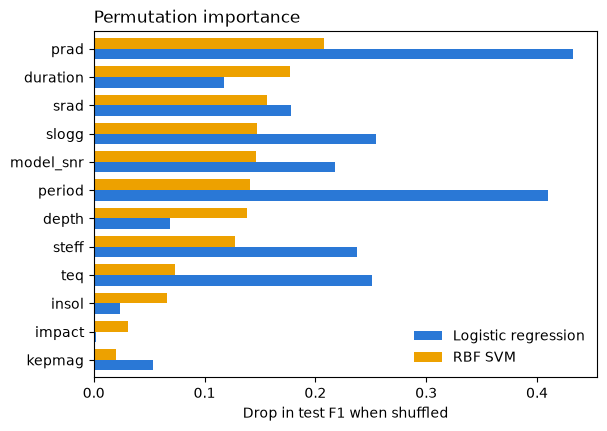

,Logistic regression,RBF SVM
prad,0.433,0.208
duration,0.117,0.177
srad,0.178,0.156
slogg,0.255,0.148
model_snr,0.218,0.147
period,0.410,0.141
depth,0.069,0.138
steff,0.238,0.128
teq,0.252,0.073
insol,0.023,0.066


In [21]:
COLORS = {"Logistic regression": "#2a78d6", "Linear SVM": "#eb6834", "Polynomial SVM": "#1baf7a", "RBF SVM": "#eda100"}
imp = {}
for name in ["Logistic regression", "RBF SVM"]:
    r = permutation_importance(best[name], X_test, y_test, scoring="f1", n_repeats=10, random_state=SEED, n_jobs=-1)
    imp[name] = r.importances_mean
imp = pd.DataFrame(imp, index=[f.replace("koi_", "") for f in FEATURES]).sort_values("RBF SVM")

ax = imp.plot.barh(figsize=(6.5, 4.5), color=[COLORS[c] for c in imp.columns], width=.75)
ax.set_xlabel("Drop in test F1 when shuffled"); ax.set_title("Permutation importance", loc="left")
ax.legend(frameon=False); plt.show()
imp.sort_values("RBF SVM", ascending=False).round(3)

**Which variables matter?** The two models use the data differently. Logistic regression leans heavily on planet radius (0.41) and insolation (0.44), with period, signal to noise, and surface gravity next. The RBF SVM spreads its importance much more evenly across duration, radius, depth, signal to noise, and stellar radius, all around 0.15 to 0.18. That fits what a curved model can do: planet radius is basically transit depth combined with stellar radius, so the RBF SVM can get that information from depth and stellar radius together, while logistic regression needs the precomputed radius column. Impact parameter and Kepler magnitude (star brightness) matter least for both. One caveat is that shuffling a column that's strongly correlated with another can understate its importance, because the model can partly fall back on the correlated one.

## A pair of variables and the decision boundary

We refit each model using only signal to noise and transit duration (both log scaled), so we can plot the boundary in two dimensions. This is just for building intuition. The full models use all 12 features.

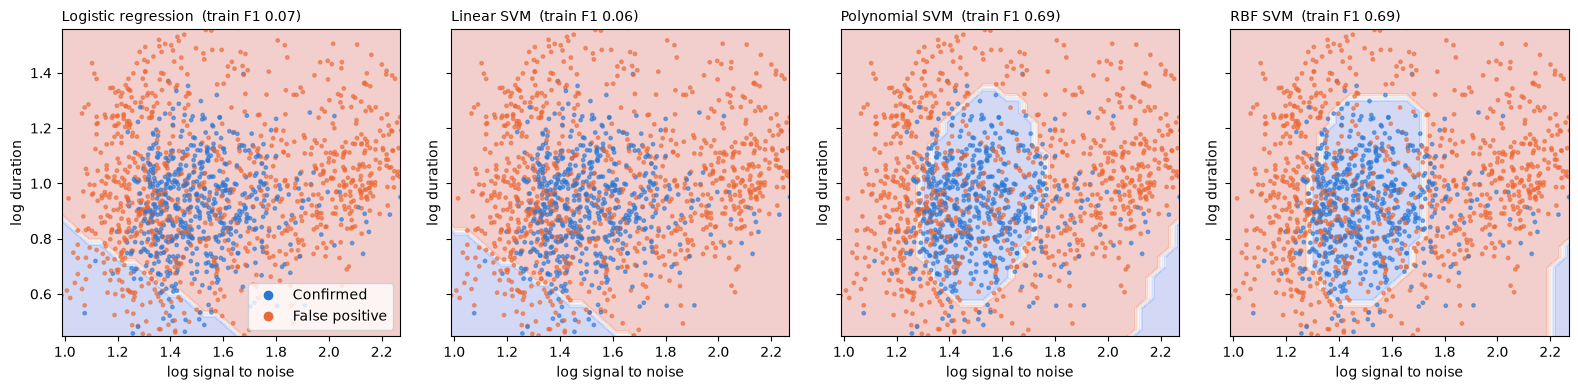

In [22]:
pair = ["koi_model_snr", "koi_duration"]
X2 = X_train[pair].to_numpy()
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
show = np.random.default_rng(SEED).choice(len(X2), 1500, replace=False)
for ax, (name, m) in zip(axes, best.items()):
    m2 = make_pipe(m["model"]).fit(X2, y_train)
    DecisionBoundaryDisplay.from_estimator(m2, X2, response_method="predict", ax=ax, alpha=.25, cmap="coolwarm_r",
                                           xlabel="log signal to noise", ylabel="log duration")
    ax.scatter(X2[show, 0], X2[show, 1], c=np.where(y_train[show] == 1, "#2a78d6", "#eb6834"), s=6, alpha=.6)
    ax.set_title(f"{name}  (train F1 {f1_score(y_train, m2.predict(X2)):.2f})", loc="left", fontsize=10)
    ax.set_xlim(np.percentile(X2[:, 0], [.5, 99.5])); ax.set_ylim(np.percentile(X2[:, 1], [.5, 99.5]))
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color="#2a78d6", label="Confirmed"),
                        plt.Line2D([], [], marker="o", ls="", color="#eb6834", label="False positive")], frameon=True)
plt.tight_layout(); plt.show()

**The decision boundary.** This plot shows why the curved models win. Confirmed planets sit in the middle of the signal to noise range, and false positives surround them on both sides: weak signals on the left and very strong ones (often eclipsing stars) on the right. A straight line can't fence in a middle region, so with only these two features logistic regression and the linear SVM end up calling almost everything a false positive (train F1 0.13 and 0.10). Both kernel SVMs draw a closed region around the planets and reach F1 0.69 from just two variables. The small extra region in the polynomial SVM's bottom right corner is an artifact of the polynomial shape, not something the data supports.

## MAGIC Gamma Telescope Classification

The obective of this analysis is to investigate whether logistic regression and SVMs can distinguish between gamma-ray and hadron events using measurements collected from the MAGIC Gamma Telescope dataset provided [here](https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope).

The target variable is `class`, which identifies whether the observed event is a gamma-ray event (`g`) or a hadron event (`h`) which makes the dataset suitable for binary classification.

## EDA


In [3]:
# Imports of highest import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
import time

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42

In [4]:
columns = [
    "fLength",
    "fWidth",
    "fSize",
    "fConc",
    "fConc1",
    "fAsym",
    "fM3Long",
    "fM3Trans",
    "fAlpha",
    "fDist",
    "class"
]

df = pd.read_csv(
    "data/magic04.data",
    header=None,
    names=columns
)

print("Dataset dimensions:", df.shape)
print("\nNumber of observations:", df.shape[0])
print("Number of columns:", df.shape[1])
df.head()

Dataset dimensions: (19020, 11)

Number of observations: 19020
Number of columns: 11


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [5]:
print(df["class"].value_counts())

print("\nClass proportions:")
print(df["class"].value_counts(normalize=True) * 100)
df.info()
df.isnull().sum()
df.describe().T

class
g    12332
h     6688
Name: count, dtype: int64

Class proportions:
class
g    64.837014
h    35.162986
Name: proportion, dtype: float64
<class 'pandas.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   fLength   19020 non-null  float64
 1   fWidth    19020 non-null  float64
 2   fSize     19020 non-null  float64
 3   fConc     19020 non-null  float64
 4   fConc1    19020 non-null  float64
 5   fAsym     19020 non-null  float64
 6   fM3Long   19020 non-null  float64
 7   fM3Trans  19020 non-null  float64
 8   fAlpha    19020 non-null  float64
 9   fDist     19020 non-null  float64
 10  class     19020 non-null  str    
dtypes: float64(10), str(1)
memory usage: 1.6 MB


,count,mean,std,min,25%,50%,75%,max
fLength,19020.0,53.250154,42.364855,4.2835,24.336000,37.14770,70.122175,334.1770
fWidth,19020.0,22.180966,18.346056,0.0000,11.863800,17.13990,24.739475,256.3820
fSize,19020.0,2.825017,0.472599,1.9413,2.477100,2.73960,3.101600,5.3233
fConc,19020.0,0.380327,0.182813,0.0131,0.235800,0.35415,0.503700,0.8930
fConc1,19020.0,0.214657,0.110511,0.0003,0.128475,0.19650,0.285225,0.6752
fAsym,19020.0,-4.331745,59.206062,-457.9161,-20.586550,4.01305,24.063700,575.2407
fM3Long,19020.0,10.545545,51.000118,-331.7800,-12.842775,15.31410,35.837800,238.3210
fM3Trans,19020.0,0.249726,20.827439,-205.8947,-10.849375,0.66620,10.946425,179.8510
fAlpha,19020.0,27.645707,26.103621,0.0000,5.547925,17.67950,45.883550,90.0000
fDist,19020.0,193.818026,74.731787,1.2826,142.492250,191.85145,240.563825,495.5610


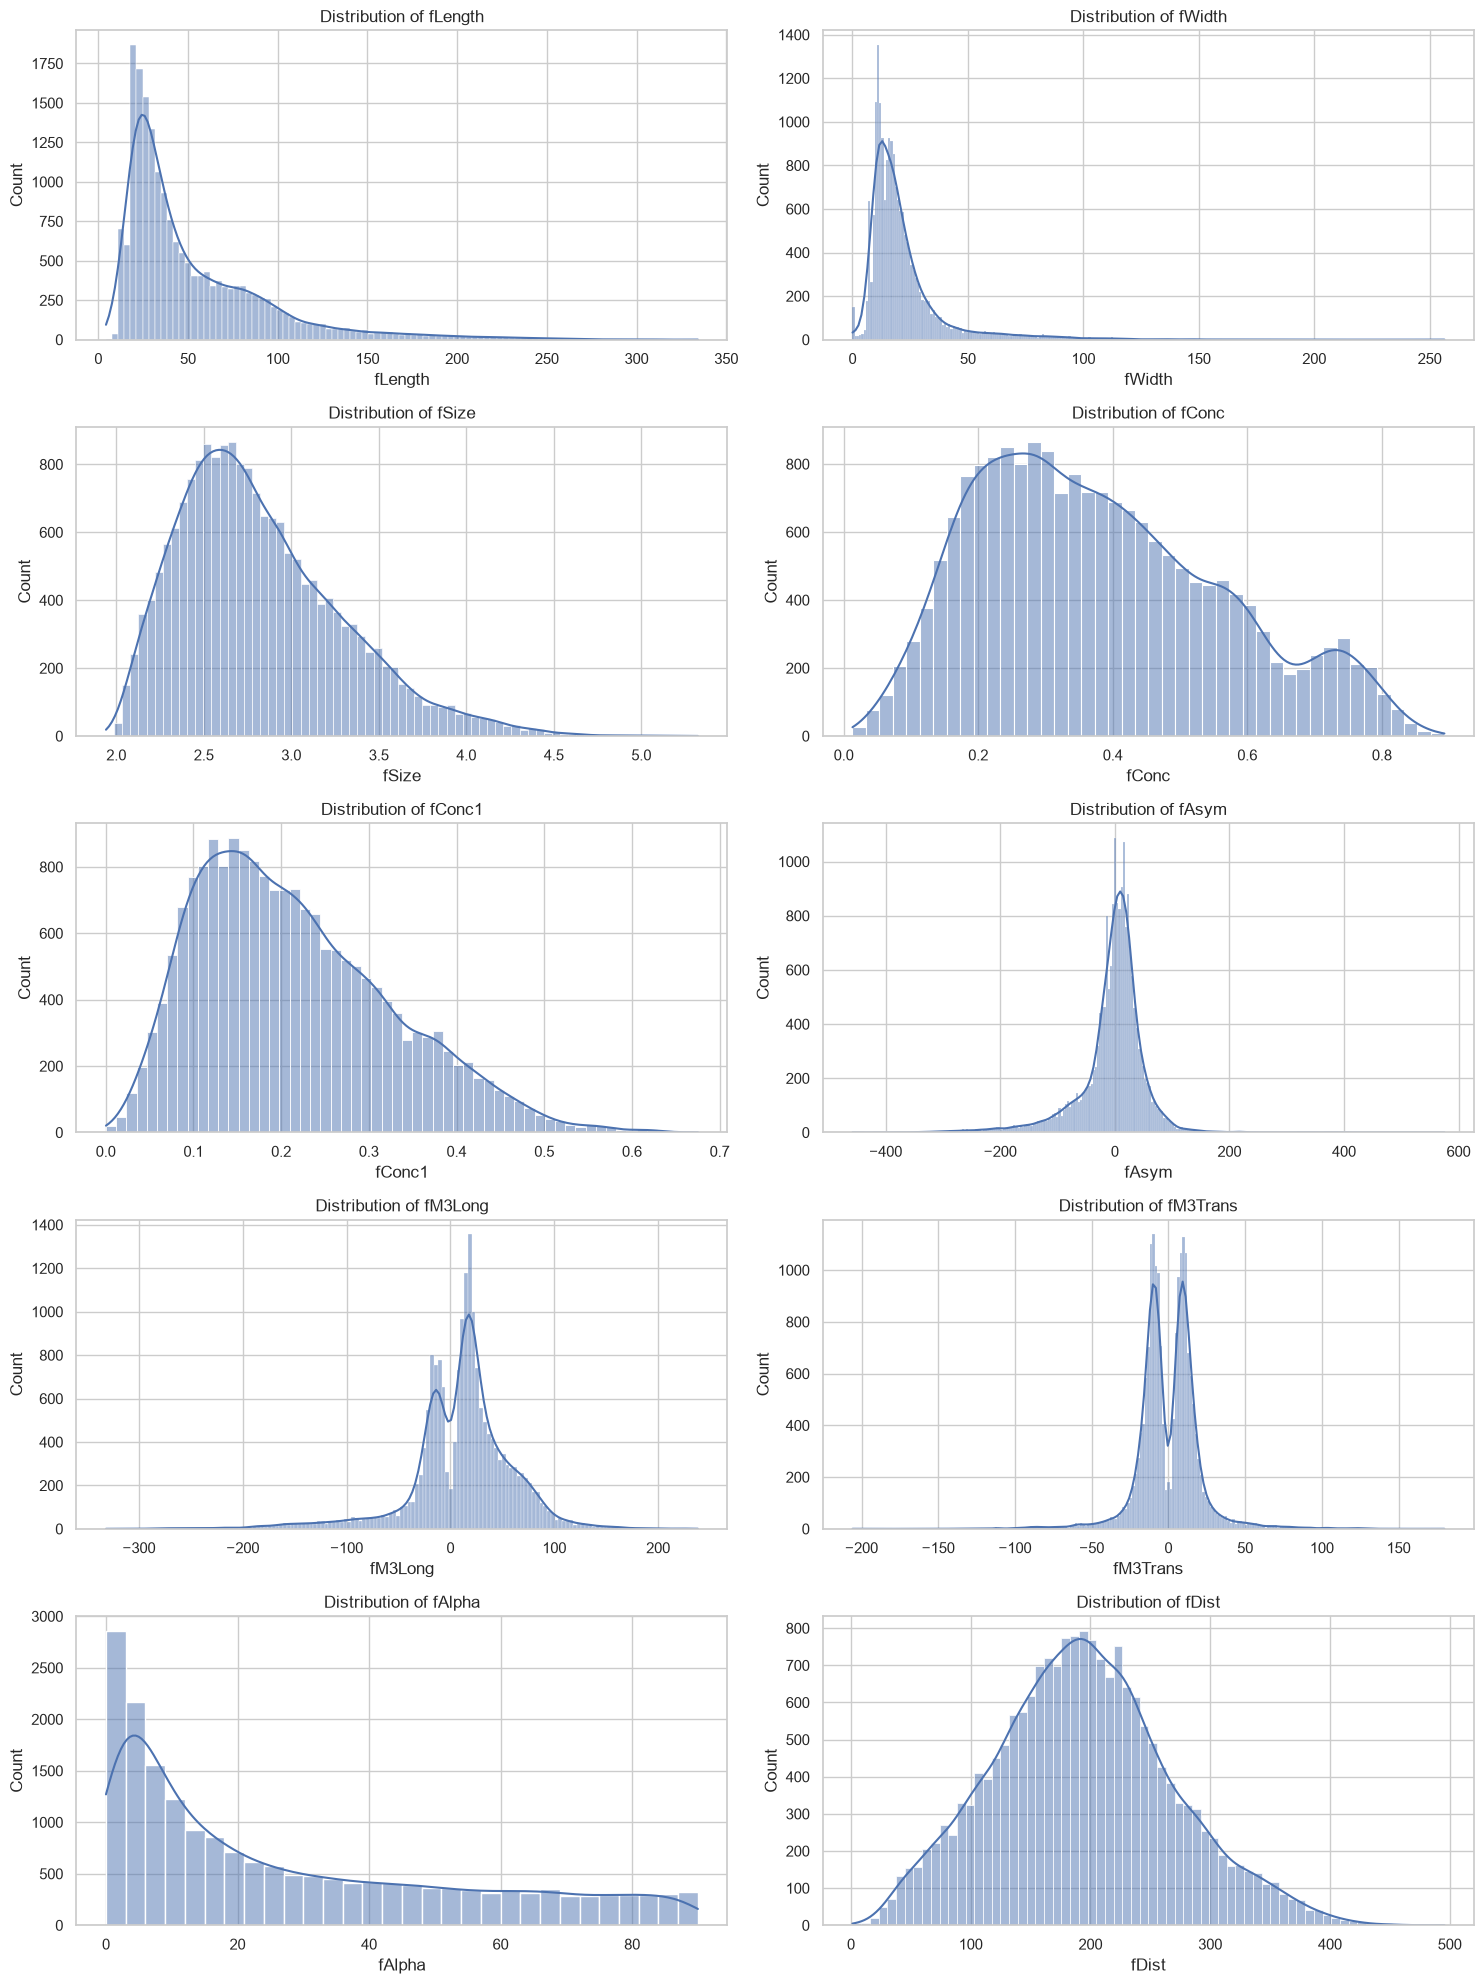

In [6]:
features = df.drop(columns="class")
fig, axes = plt.subplots(5, 2, figsize=(15, 20))
for i, column in enumerate(features.columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i // 2, i % 2]
    )
    axes[i // 2, i % 2].set_title(f"Distribution of {column}")
plt.tight_layout()
plt.show()

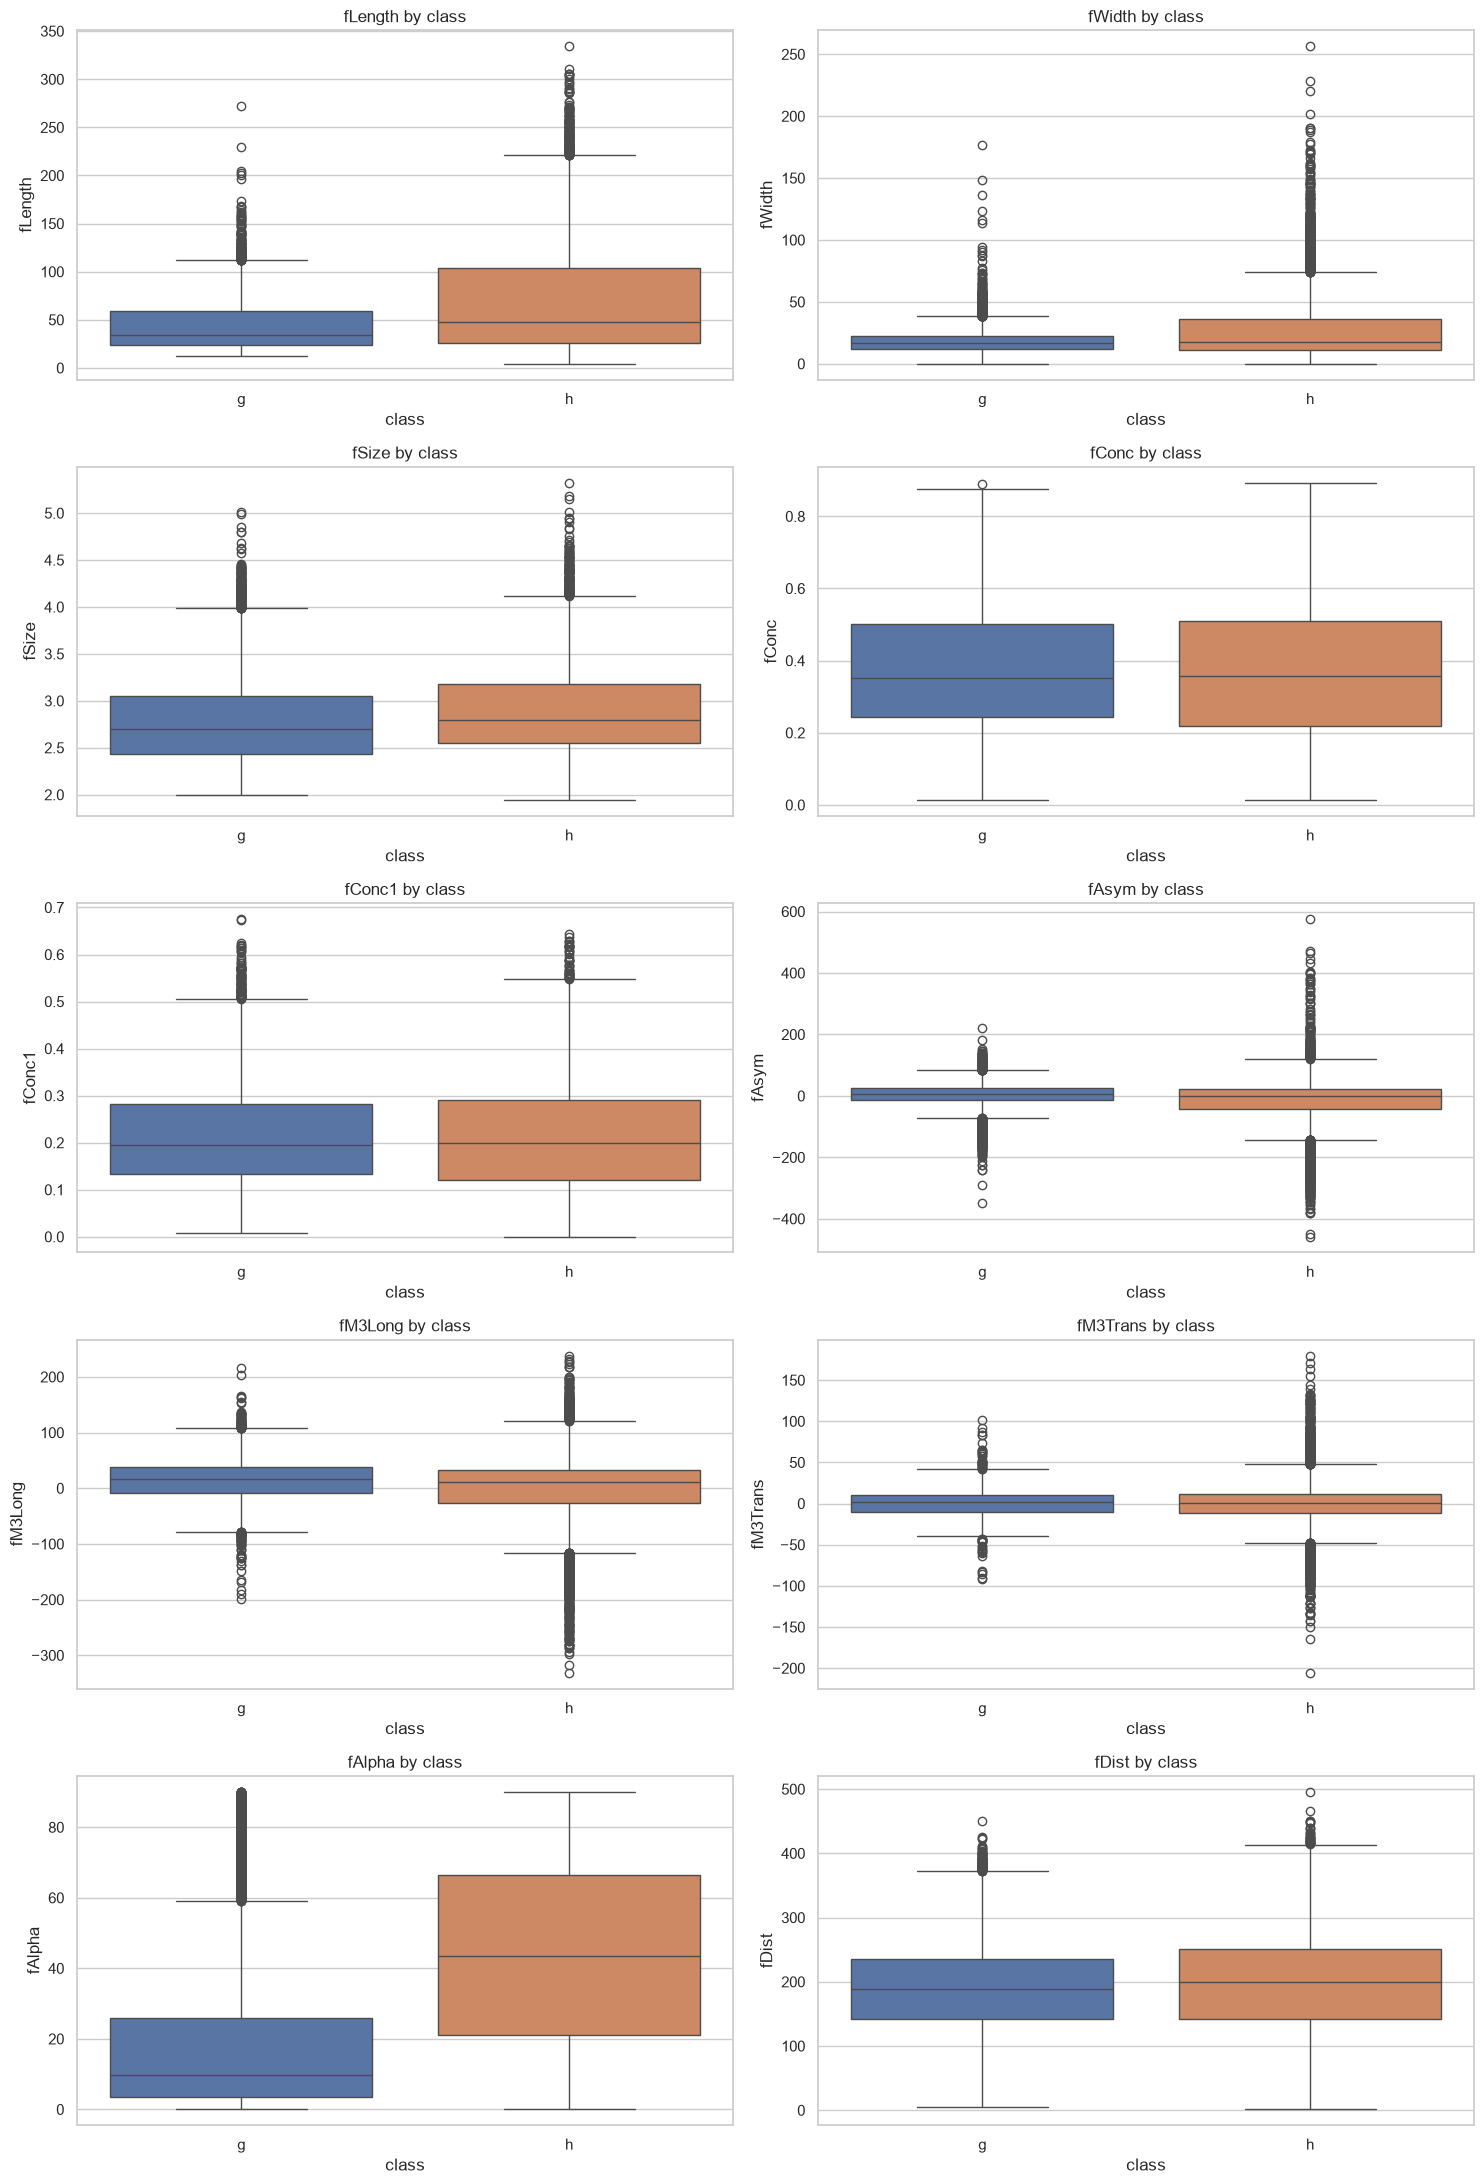

In [7]:
fig, axes = plt.subplots(5, 2, figsize=(15, 22))
for i, column in enumerate(features.columns):
    sns.boxplot(
        data=df,
        x="class",
        y=column,
        hue="class",
        legend=False,
        ax=axes[i // 2, i % 2]
    )
    axes[i // 2, i % 2].set_title(f"{column} by class")
plt.tight_layout()
plt.show()


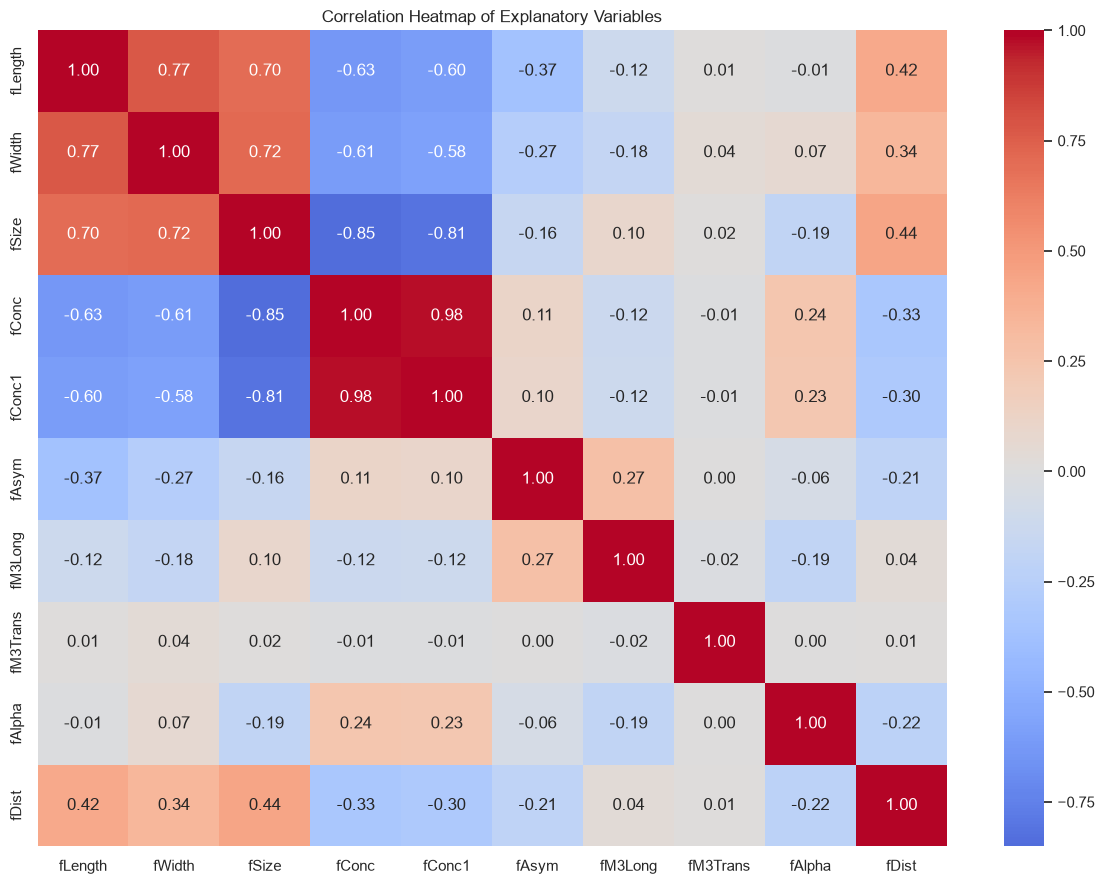

In [8]:
correlation_matrix = features.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Heatmap of Explanatory Variables")
plt.tight_layout()
plt.show()

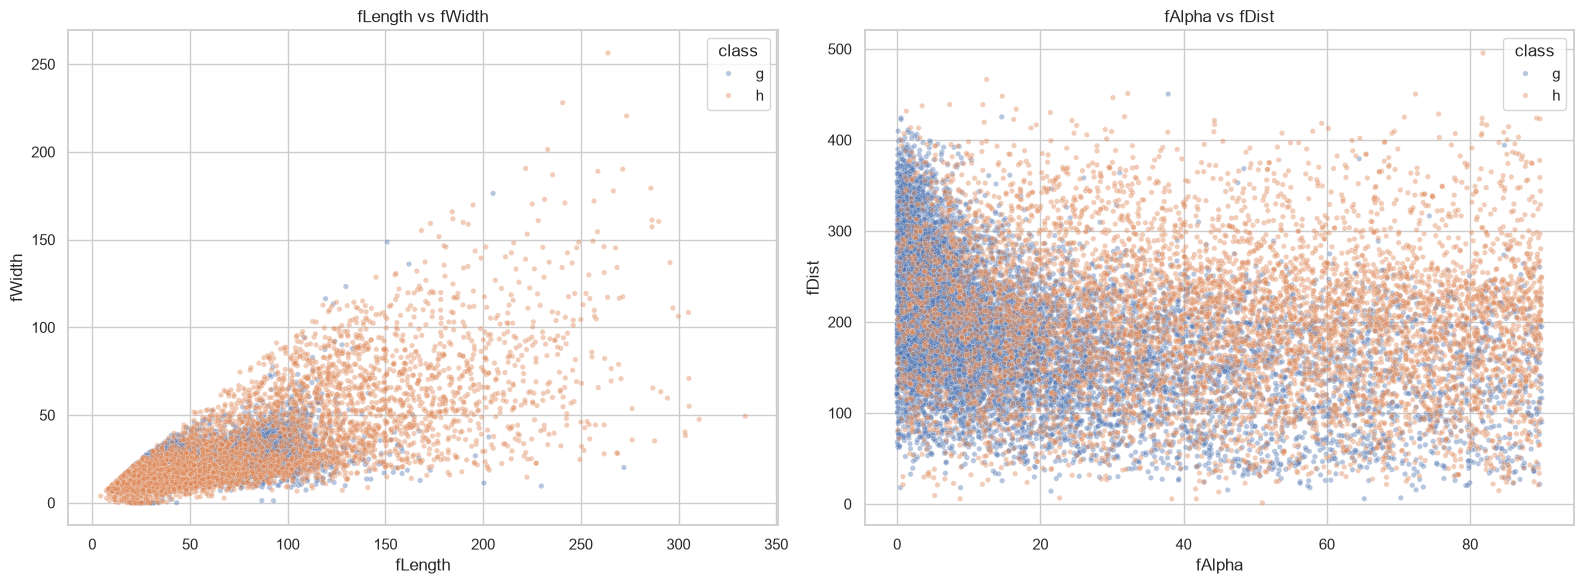

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(
    data=df,
    x="fLength",
    y="fWidth",
    hue="class",
    alpha=0.4,
    s=15,
    ax=axes[0]
)
axes[0].set_title("fLength vs fWidth")
sns.scatterplot(
    data=df,
    x="fAlpha",
    y="fDist",
    hue="class",
    alpha=0.4,
    s=15,
    ax=axes[1]
)
axes[1].set_title("fAlpha vs fDist")
plt.tight_layout()
plt.show()


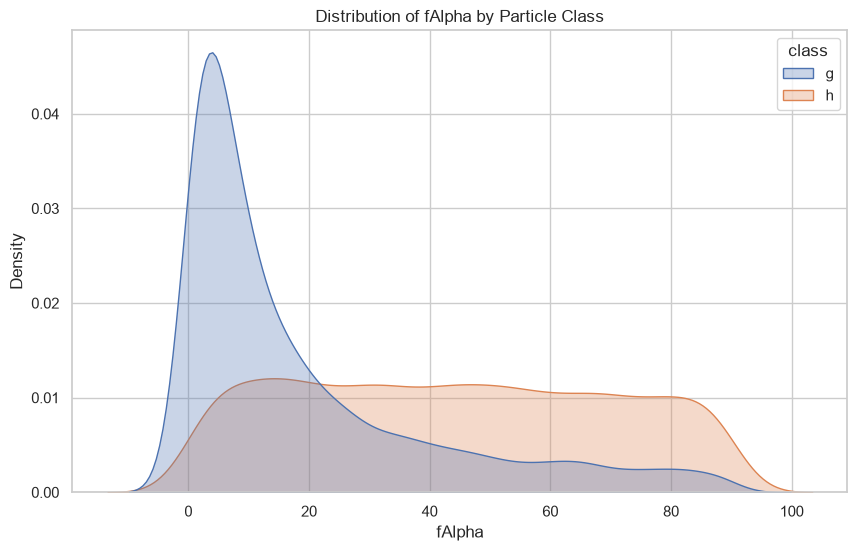

class,g,h
fLength,34.55800,47.90540
fWidth,17.05330,17.38415
fSize,2.70480,2.79765
fConc,0.35260,0.35800
fConc1,0.19500,0.20025
fAsym,6.63815,-1.53960
fM3Long,16.91265,11.12460
fM3Trans,1.32800,0.38260
fAlpha,9.70815,43.38290
fDist,188.12000,199.86955


In [10]:
plt.figure(figsize=(10, 6))
sns.kdeplot(
    data=df,
    x="fAlpha",
    hue="class",
    fill=True,
    common_norm=False,
    alpha=0.3
)
plt.title("Distribution of fAlpha by Particle Class")
plt.xlabel("fAlpha")
plt.ylabel("Density")
plt.show()
df.groupby("class")[features.columns].median().T

### Observations

Chances are fAlpha will be our most promising indicator, and it should be noted that the strong correlation between some variables may indicate some overlapping information. The skewed distributions of fLength, fWidth, fSize, and fAlpha may also indicate some extreme observations to keep in mind. There's also a large class imbalance, so a classifier predicting gamma (`g`) for every observation would be 64.84% accurate. This is the minimum we need to beat!

## Logistic Regression

In [11]:
X = df.drop(columns="class")
y = df["class"]

# 80/20 test split, seed is 42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))
print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))

Training observations: 15216
Testing observations: 3804

Training class proportions:
class
g    0.648396
h    0.351604
Name: proportion, dtype: float64

Testing class proportions:
class
g    0.648265
h    0.351735
Name: proportion, dtype: float64


In [12]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Keep track of training runtime
start_time = time.perf_counter()
logistic_model.fit(X_train, y_train)
logistic_training_time = time.perf_counter() - start_time

# Generate predictions
y_pred = logistic_model.predict(X_test)

# Calculate prediction probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate performance
print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label="g"))
print("Recall:", recall_score(y_test, y_pred, pos_label="g"))
print("F1-score:", f1_score(y_test, y_pred, pos_label="g"))
print("ROC-AUC:", roc_auc_score(y_test == "g", y_prob))
gamma_index = list(logistic_model.classes_).index("g")
y_prob = logistic_model.predict_proba(X_test)[:, gamma_index]
# Calculate ROC-AUC using gamma as the positive class
auc = roc_auc_score(
    (y_test == "g").astype(int),
    y_prob
)
print("Corrected ROC-AUC:", auc)

print("Training time:", logistic_training_time, "seconds")

Logistic Regression Results
---------------------------
Accuracy: 0.7991587802313355
Precision: 0.8087808417997098
Recall: 0.9038929440389294
F1-score: 0.8536959019532746
ROC-AUC: 0.1530991893336825
Corrected ROC-AUC: 0.8469008106663175
Training time: 0.04570479199901456 seconds


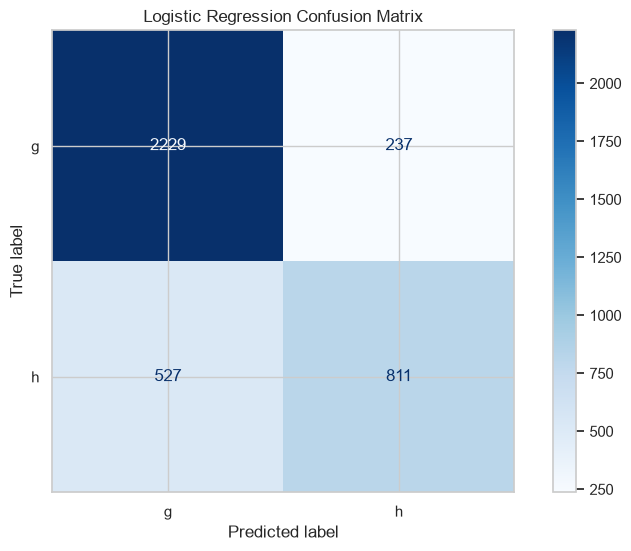

In [13]:
ConfusionMatrixDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

    Feature  Coefficient  Absolute Coefficient
0   fLength     1.201220              1.201220
8    fAlpha     1.167837              1.167837
4    fConc1     0.555258              0.555258
6   fM3Long    -0.334168              0.334168
2     fSize     0.301297              0.301297
1    fWidth     0.109836              0.109836
9     fDist     0.046349              0.046349
7  fM3Trans    -0.025791              0.025791
3     fConc     0.018162              0.018162
5     fAsym    -0.016118              0.016118


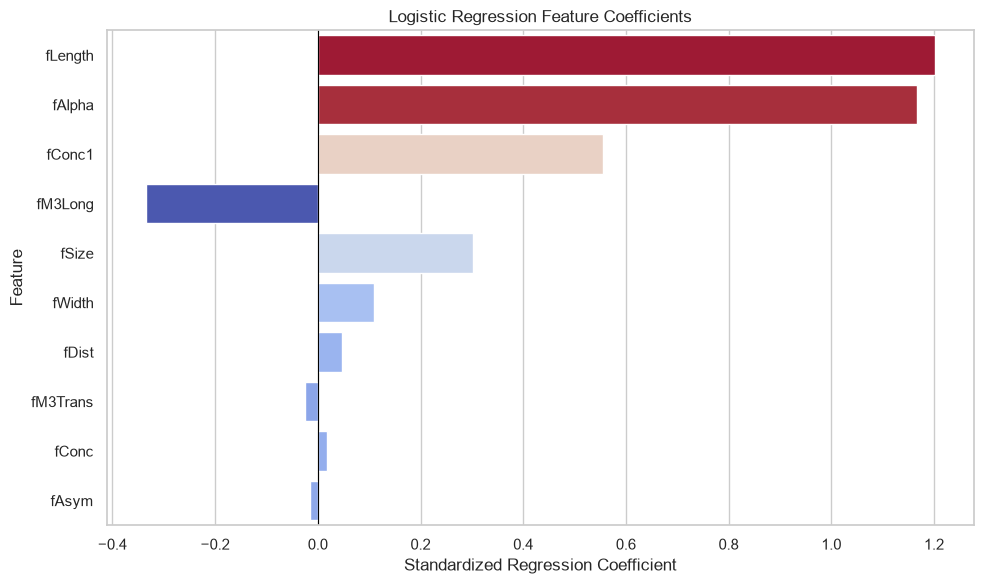

In [14]:
# Extract logistic regression coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.named_steps["classifier"].coef_[0]
})

# Sort by absolute coefficient magnitude
coefficients["Absolute Coefficient"] = (
    coefficients["Coefficient"].abs()
)
coefficients = coefficients.sort_values(
    "Absolute Coefficient",
    ascending=False
)
print(coefficients)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature",
    hue="Coefficient",
    palette="coolwarm",
    legend=False
)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Standardized Regression Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           g       0.81      0.90      0.85      2466
           h       0.77      0.61      0.68      1338

    accuracy                           0.80      3804
   macro avg       0.79      0.76      0.77      3804
weighted avg       0.80      0.80      0.79      3804



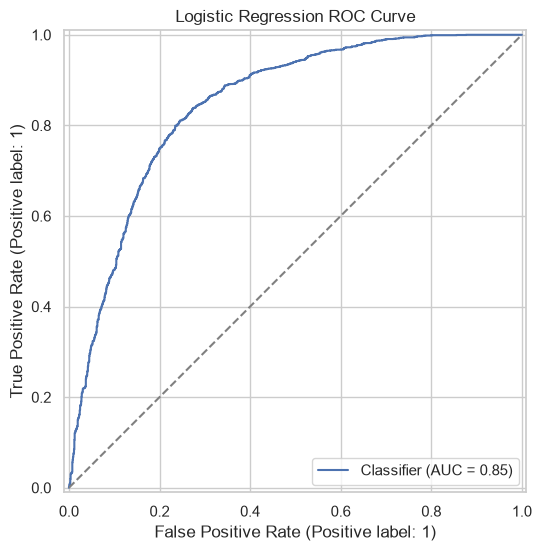

In [15]:
print(classification_report(y_test, y_pred))
RocCurveDisplay.from_predictions(
    (y_test == "g").astype(int),
    y_prob
)

plt.title("Logistic Regression ROC Curve")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.show()

### Some observations

The initial results suggest that fLength and fAlpha are the most important predictors with fConc1, fM3Long, and fSize providing some additional information.

The model has high gamma recall but low hadron recall, which indicates that it's able to identify most gamma observations but misses quite a few hadron observations. We'll have to investigate class_weight='balanced' later.

## Linear SVM

In [17]:
# Create Linear SVM pipeline
linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=10000,
        random_state=RANDOM_STATE
    ))
])

# Train and measure runtime
start_time = time.perf_counter()

linear_svm.fit(X_train, y_train)
linear_svm_training_time = time.perf_counter() - start_time
svm_pred = linear_svm.predict(X_test)
svm_scores = linear_svm.decision_function(X_test)

# LinearSVC's positive decision scores correspond to classes_[1].
# Our desired positive class is gamma, classes_[0].
gamma_scores = -svm_scores

# Calculate metrics
print("Linear SVM Results")
print("------------------")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(
    y_test, svm_pred, pos_label="g"
))
print("Recall:", recall_score(
    y_test, svm_pred, pos_label="g"
))
print("F1-score:", f1_score(
    y_test, svm_pred, pos_label="g"
))
print("ROC-AUC:", roc_auc_score(
    (y_test == "g").astype(int),
    gamma_scores
))
print("Training time:", linear_svm_training_time, "seconds")

Linear SVM Results
------------------
Accuracy: 0.7981072555205048
Precision: 0.8062770562770563
Recall: 0.9063260340632603
F1-score: 0.8533791523482245
ROC-AUC: 0.8470556822411099
Training time: 0.04375120899931062 seconds


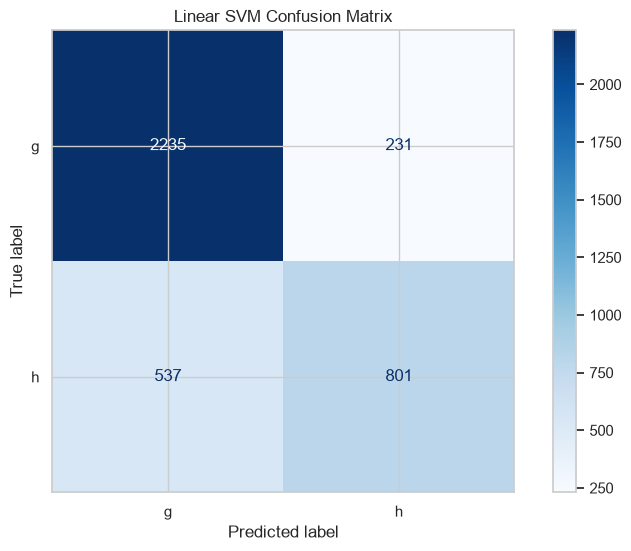

              precision    recall  f1-score   support

           g       0.81      0.91      0.85      2466
           h       0.78      0.60      0.68      1338

    accuracy                           0.80      3804
   macro avg       0.79      0.75      0.76      3804
weighted avg       0.80      0.80      0.79      3804



In [18]:
ConfusionMatrixDisplay.from_estimator(
    linear_svm,
    X_test,
    y_test,
    cmap="Blues"
)

plt.title("Linear SVM Confusion Matrix")
plt.show()

print(classification_report(y_test, svm_pred))

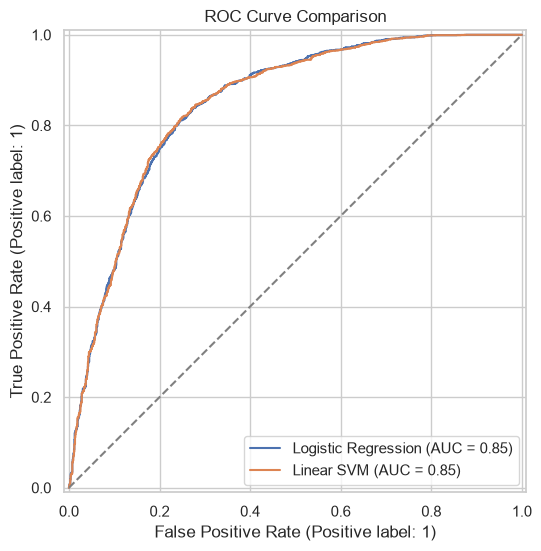

In [19]:
fig, ax = plt.subplots(figsize=(9, 6))

RocCurveDisplay.from_predictions(
    (y_test == "g").astype(int),
    y_prob,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    (y_test == "g").astype(int),
    gamma_scores,
    name="Linear SVM",
    ax=ax
)

ax.plot([0, 1], [0, 1], "--", color="grey")

plt.title("ROC Curve Comparison")
plt.show()

In [20]:
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="g"),
        "Recall": recall_score(y_test, y_pred, pos_label="g"),
        "F1-score": f1_score(y_test, y_pred, pos_label="g"),
        "ROC-AUC": roc_auc_score(
            (y_test == "g").astype(int), y_prob
        ),
        "Training Time": logistic_training_time
    },
    {
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(y_test, svm_pred),
        "Precision": precision_score(y_test, svm_pred, pos_label="g"),
        "Recall": recall_score(y_test, svm_pred, pos_label="g"),
        "F1-score": f1_score(y_test, svm_pred, pos_label="g"),
        "ROC-AUC": roc_auc_score(
            (y_test == "g").astype(int), gamma_scores
        ),
        "Training Time": linear_svm_training_time
    }
])

results.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time
0,Logistic Regression,0.7992,0.8088,0.9039,0.8537,0.8469,0.0457
1,Linear SVM,0.7981,0.8063,0.9063,0.8534,0.8471,0.0438


## Class weight Investigation

As we've discovered, the classes are not well balanced at all, so lets check how changing class_weight to be balanced affects things. My assumption is that we'll see improved metrics for hadron observations at the expense of gamma observations.

In [21]:
logistic_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

logistic_balanced.fit(X_train, y_train)

balanced_pred = logistic_balanced.predict(X_test)

print(classification_report(y_test, balanced_pred))

              precision    recall  f1-score   support

           g       0.85      0.83      0.84      2466
           h       0.70      0.73      0.71      1338

    accuracy                           0.79      3804
   macro avg       0.77      0.78      0.78      3804
weighted avg       0.80      0.79      0.79      3804



## Polynomial SVMs

We used a linear SVM earlier, but I wonder how overfitting these things with more complex polynomials would work out. I'm sure we'll see improved scores in the training data but the tests will be worse off.

In [22]:
# Polynomial SVM model
poly_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="poly",
        degree=3,
        C=1.0,
        gamma="scale",
        class_weight=None
    ))
])

start_time = time.perf_counter()

poly_svm.fit(X_train, y_train)
poly_training_time = time.perf_counter() - start_time
poly_pred = poly_svm.predict(X_test)

# SVC decision scores are positive for hadron observations
poly_scores = -poly_svm.decision_function(X_test)

print("Polynomial SVM Results")
print("----------------------")
print("Accuracy:", accuracy_score(y_test, poly_pred))
print("Precision:", precision_score(
    y_test, poly_pred, pos_label="g"
))
print("Recall:", recall_score(
    y_test, poly_pred, pos_label="g"
))
print("F1-score:", f1_score(
    y_test, poly_pred, pos_label="g"
))
print("ROC-AUC:", roc_auc_score(
    (y_test == "g").astype(int),
    poly_scores
))
print("Training time:", poly_training_time)
print("----------------------")
print(classification_report(
    y_test,
    poly_pred
))

Polynomial SVM Results
----------------------
Accuracy: 0.812565720294427
Precision: 0.7859706362153345
Recall: 0.9768856447688564
F1-score: 0.8710902187669499
ROC-AUC: 0.8819466417417384
Training time: 1.8353518750009243
----------------------
              precision    recall  f1-score   support

           g       0.79      0.98      0.87      2466
           h       0.92      0.51      0.66      1338

    accuracy                           0.81      3804
   macro avg       0.85      0.74      0.76      3804
weighted avg       0.83      0.81      0.80      3804



In [23]:
# RBF SBF Model
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight=None
    ))
])

start_time = time.perf_counter()

rbf_svm.fit(X_train, y_train)
rbf_training_time = time.perf_counter() - start_time
rbf_pred = rbf_svm.predict(X_test)
rbf_scores = -rbf_svm.decision_function(X_test)

print("RBF SVM Results")
print("----------------")
print("Accuracy:", accuracy_score(y_test, rbf_pred))
print("Precision:", precision_score(
    y_test, rbf_pred, pos_label="g"
))
print("Recall:", recall_score(
    y_test, rbf_pred, pos_label="g"
))
print("F1-score:", f1_score(
    y_test, rbf_pred, pos_label="g"
))
print("ROC-AUC:", roc_auc_score(
    (y_test == "g").astype(int),
    rbf_scores
))
print("Training time:", rbf_training_time)
print("----------------------")
print(classification_report(
    y_test,
    rbf_pred
))

RBF SVM Results
----------------
Accuracy: 0.8730283911671924
Precision: 0.8619934282584885
Recall: 0.9574209245742092
F1-score: 0.9072046109510087
ROC-AUC: 0.9223135691745558
Training time: 1.3381816250002885
----------------------
              precision    recall  f1-score   support

           g       0.86      0.96      0.91      2466
           h       0.90      0.72      0.80      1338

    accuracy                           0.87      3804
   macro avg       0.88      0.84      0.85      3804
weighted avg       0.88      0.87      0.87      3804



### Observations

It appears just from looking at the numbers that the models have improved their performance, but the runtime has gone up significantly compared to the linear SVM and logistic regression models. However, let's check the balanced class weights with the RBF SVMs to see if that improves what appears to be the best-performing model.

## RBF SVM Class Weight Check

In [24]:
rbf_svm_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    ))
])

rbf_svm_balanced.fit(X_train, y_train)

rbf_balanced_pred = rbf_svm_balanced.predict(X_test)

print(classification_report(
    y_test,
    rbf_balanced_pred
))

              precision    recall  f1-score   support

           g       0.90      0.90      0.90      2466
           h       0.82      0.81      0.81      1338

    accuracy                           0.87      3804
   macro avg       0.86      0.85      0.86      3804
weighted avg       0.87      0.87      0.87      3804



### Observations

It appears just from looking at the numbers that the models improved their score, but the runtime has gone up significantly for both of these models and the improvement wasn't too much higher.

## Overall Results Comparison Table

In [25]:
models = {
    "Logistic Regression": (logistic_model, y_pred),
    "Logistic Regression Balanced": (logistic_balanced, balanced_pred),
    "Linear SVM": (linear_svm, svm_pred),
    "Polynomial SVM": (poly_svm, poly_pred),
    "RBF SVM": (rbf_svm, rbf_pred),
    "RBF SVM Balanced": (rbf_svm_balanced, rbf_balanced_pred)
}

model_results = []

for name, (model, predictions) in models.items():

    scores = -model.decision_function(X_test)

    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="g"
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="g"
        ),
        "F1-score": f1_score(
            y_test, predictions, pos_label="g"
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "g").astype(int), scores
        )
    })

comparison = pd.DataFrame(model_results)

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score,Macro F1,ROC-AUC
0,Logistic Regression,0.7992,0.8088,0.9039,0.8537,0.7667,0.8469
1,Logistic Regression Balanced,0.7936,0.8512,0.8260,0.8384,0.7764,0.8496
2,Linear SVM,0.7981,0.8063,0.9063,0.8534,0.7647,0.8471
3,Polynomial SVM,0.8126,0.7860,0.9769,0.8711,0.7639,0.8819
4,RBF SVM,0.8730,0.8620,0.9574,0.9072,0.8531,0.9223
5,RBF SVM Balanced,0.8688,0.8961,0.9023,0.8992,0.8558,0.9245


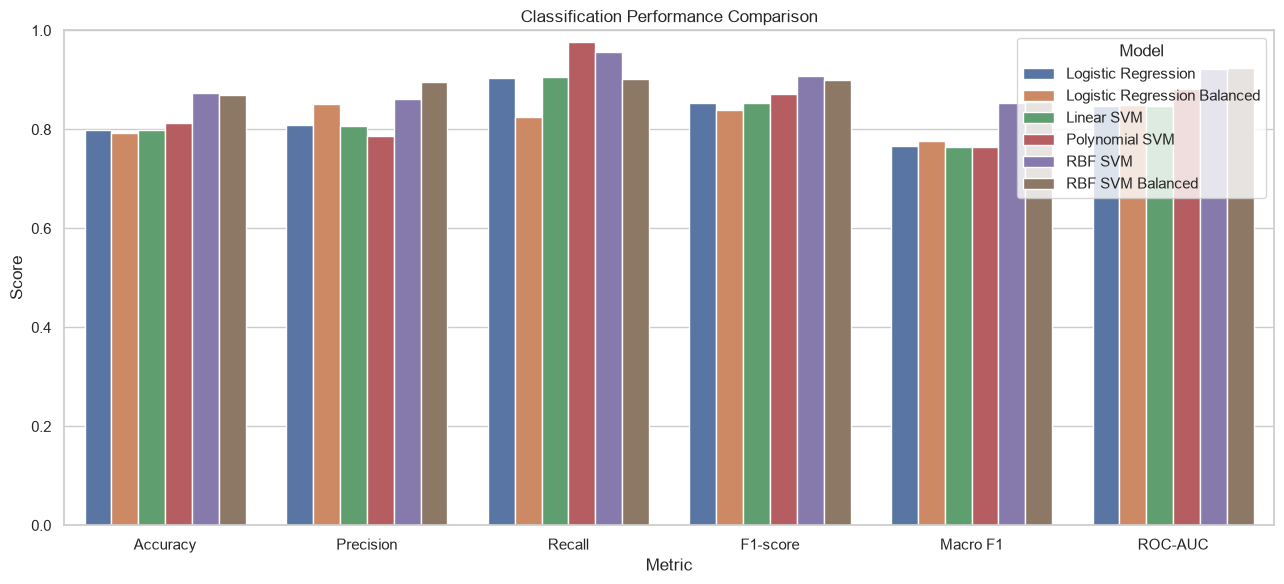

In [26]:
comparison_melted = comparison.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Macro F1",
        "ROC-AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=comparison_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Classification Performance Comparison")
plt.tight_layout()
plt.show()

## Cross Validation and Hyperparameters

At the moment, we're only evaluating with one split. Lets introduce cross validation and see how consistent the performance is. We shoudl also check if we're beholden to different hyperparameters.

In [27]:
from sklearn.model_selection import (
    cross_validate,
    StratifiedKFold
)

# Define the cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Models to evaluate
models = {
    "Logistic Regression": logistic_model,
    "Logistic Regression Balanced": logistic_balanced,
    "Linear SVM": linear_svm,
    "Polynomial SVM": poly_svm,
    "RBF SVM": rbf_svm,
    "RBF SVM Balanced": rbf_svm_balanced
}

# Metrics to evaluate
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models.items():

    start_time = time.perf_counter()

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    training_time = time.perf_counter() - start_time

    result = {
        "Model": name,
        "Macro F1 Mean": scores["test_f1"].mean(),
        "Macro F1 Std": scores["test_f1"].std(),
        "Training Time": training_time,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    }

    cv_results.append(result)

# Create comparison DataFrame
cv_comparison = pd.DataFrame(cv_results)

cv_comparison = cv_comparison.sort_values(
    by="Macro F1 Mean",
    ascending=False
)

cv_comparison.round(4)

,Model,Macro F1 Mean,Macro F1 Std,Training Time,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,ROC-AUC Mean,ROC-AUC Std
5,RBF SVM Balanced,0.8456,0.0043,2.1423,0.8596,0.0035,0.8466,0.8447,0.9162,0.0037
4,RBF SVM,0.8445,0.0044,1.7416,0.8662,0.0036,0.8755,0.8284,0.9148,0.0040
1,Logistic Regression Balanced,0.7652,0.0074,1.0182,0.7835,0.0073,0.7628,0.7683,0.8390,0.0055
0,Logistic Regression,0.7527,0.0052,1.4948,0.7878,0.0053,0.7781,0.7413,0.8365,0.0055
2,Linear SVM,0.7510,0.0058,0.9961,0.7868,0.0059,0.7776,0.7393,0.8372,0.0054
3,Polynomial SVM,0.7500,0.0052,2.7662,0.8024,0.0041,0.8411,0.7309,0.8700,0.0058


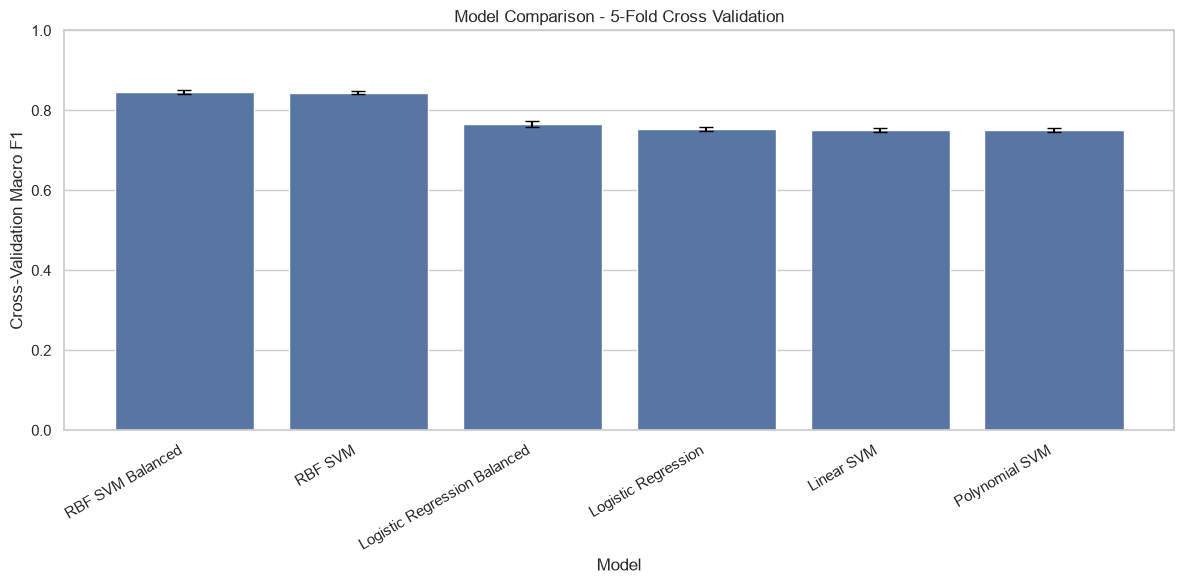

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=cv_comparison,
    x="Model",
    y="Macro F1 Mean"
)

plt.errorbar(
    x=range(len(cv_comparison)),
    y=cv_comparison["Macro F1 Mean"],
    yerr=cv_comparison["Macro F1 Std"],
    fmt="none",
    color="black",
    capsize=5
)

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.ylabel("Cross-Validation Macro F1")
plt.title("Model Comparison - 5-Fold Cross Validation")
plt.tight_layout()
plt.show()